# Hydrological Data From Fieldwork Campaign OCT2026

- Flow velocity data (eco-nortek), water level (diver)

- Request access to the data from ICOE.

In [24]:
# import statements

import pandas as pd
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)   # pandas/numpy version mismatch, harmless

figures = {}
tables = {}

# Water Level Data

Data collection:
- Measurement interval = every 15 minutes
- The healthy diver started measurements on 17:47 on 10-10
- The unhealthy diver started measurements on 17:15 on 10-10

Though both devices were turned on, they were not installed until later:
- Healthy diver was installed in the afternoon on 10-10.
- Unhealthy diver was installed in the morning on 11-10, due to time constraints. 

Low water measurements stopped at +20cm, this is when the devices failed to measure.


In [25]:
SAVE = False   # True = save figures and tables in results/ (overwrites the files there)

data_folder = Path('../data/oct2026')
fig_dir = Path('../results/oct2026')
table_dir = Path('../results/oct2026')

files = {
    "Healthy": data_folder / "LaiHoa_Healthy_Mangrove_261012103755_Y6762.CSV",
    "Unhealthy": data_folder / "LaiHoa_Unhealthy_Mangrove_261012220322_Y6818.CSV"
}

results = []


for section, file in files.items():
    df = pd.read_csv(file, skiprows=51, encoding="latin1")
    df = df[df["Date/time"].str.contains(r"\d{4}/\d{2}/\d{2}", na=False)].copy()

    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(df["Pressure[cmH2O]"], errors="coerce")
    df["Temperature[°C]"] = pd.to_numeric(df["Temperature[°C]"], errors="coerce")
    df = df.dropna(subset=["Date/time", "Pressure[cmH2O]"])

    p = df["Pressure[cmH2O]"]
    t = df["Temperature[°C]"]

    results.append({
        "Section": section,
        "Start": df["Date/time"].min(),
        "End": df["Date/time"].max(),
        "Measurements": len(df),
        "Pressure mean (cmH2O)": p.mean(),
        "Pressure std (cmH2O)": p.std(),
        "Pressure min (cmH2O)": p.min(),
        "Pressure max (cmH2O)": p.max(),
        "Pressure range (cmH2O)": p.max() - p.min(),
        "Temperature mean (°C)": t.mean(),
        "Temperature std (°C)": t.std(),
        "Temperature min (°C)": t.min(),
        "Temperature max (°C)": t.max()
    })

summary = pd.DataFrame(results).round(3)

print(summary.to_string(index=False))

  Section               Start                 End  Measurements  Pressure mean (cmH2O)  Pressure std (cmH2O)  Pressure min (cmH2O)  Pressure max (cmH2O)  Pressure range (cmH2O)  Temperature mean (°C)  Temperature std (°C)  Temperature min (°C)  Temperature max (°C)
  Healthy 2026-10-10 17:47:03 2026-10-12 10:32:03           164               1087.262                63.141              1028.133              1213.225                 185.092                 31.011                 1.293                28.880                34.593
Unhealthy 2026-10-10 17:15:36 2026-10-12 10:00:36           164               1072.404                72.007              1023.117              1242.625                 219.508                 29.962                 2.952                24.027                38.333


In [4]:

results_wl = [] #wl means water level 

for section, file in files.items():
    df = pd.read_csv(file, skiprows=51, encoding="latin1")
    df = df[df["Date/time"].str.contains(r"\d{4}/\d{2}/\d{2}", na=False)].copy()

    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(
        df["Pressure[cmH2O]"], errors="coerce"
    )
    df = df.dropna(subset=["Date/time", "Pressure[cmH2O]"])
    df = df.sort_values("Date/time")

    # convert pressure to relative wl change (cm)
    df["Water level (cm)"] = (
        df["Pressure[cmH2O]"] - df["Pressure[cmH2O]"].iloc[0]
    )

    wl = df["Water level (cm)"]

    results_wl.append({
        "Section": section,
        "Measurements": len(df),
        "Mean water level (cm)": wl.mean(),
        "Std water level (cm)": wl.std(),
        "Minimum (cm)": wl.min(),
        "Maximum (cm)": wl.max(),
        "Water-level range (cm)": wl.max() - wl.min()
    })

waterlevel_summary = pd.DataFrame(results_wl).round(2)
print(waterlevel_summary.to_string(index=False))


  Section  Measurements  Mean water level (cm)  Std water level (cm)  Minimum (cm)  Maximum (cm)  Water-level range (cm)
  Healthy           164                  59.13                 63.14          0.00        185.09                  185.09
Unhealthy           164                  49.11                 72.01         -0.18        219.33                  219.51


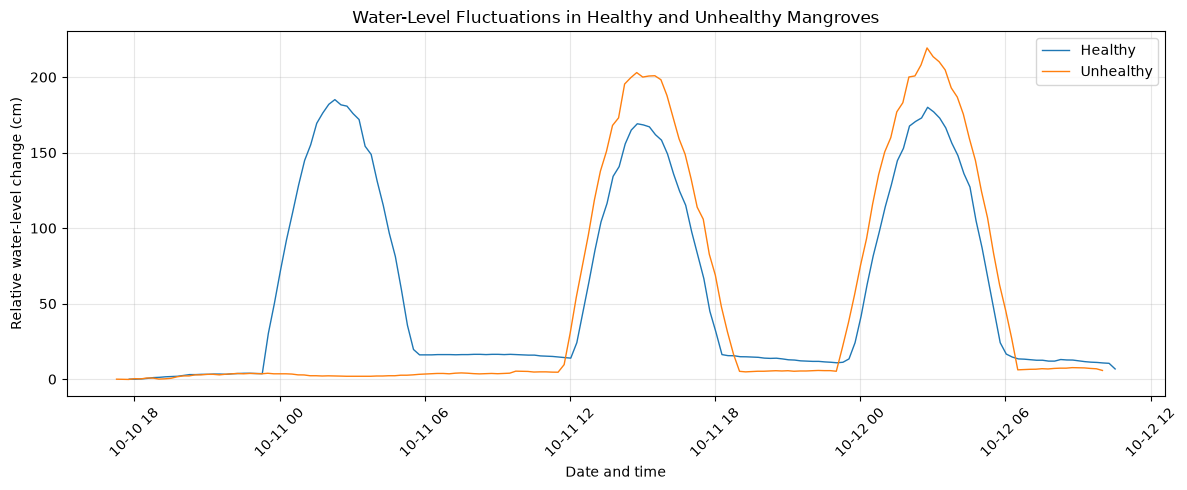

In [26]:

plt.figure(figsize=(12, 5))

for section, file in files.items():
    df = pd.read_csv(file, skiprows=51, encoding="latin1")
    df = df[df["Date/time"].str.contains(r"\d{4}/\d{2}/\d{2}", na=False)].copy()

    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(
        df["Pressure[cmH2O]"], errors="coerce"
    )
    df = df.dropna(subset=["Date/time", "Pressure[cmH2O]"])
    df = df.sort_values("Date/time")

    # Relative water-level change (cm)
    df["Water level (cm)"] = (
        df["Pressure[cmH2O]"] - df["Pressure[cmH2O]"].iloc[0]
    )

    plt.plot(
        df["Date/time"],
        df["Water level (cm)"],
        label=section,
        linewidth=1
    )

plt.xlabel("Date and time")
plt.ylabel("Relative water-level change (cm)")
plt.title("Water-Level Fluctuations in Healthy and Unhealthy Mangroves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
figures["waterlevel_relative"] = plt.gcf()
plt.show()


### Inundation time

For every delta_h the relative water level is shifted down by delta_h. Water level >= 0 counts as inundated, < 0 as dry. The time follows from the number of measurements (one every 15 minutes).

Healthy (Δh = 13.51): Dry time = 13.0 h, Inundation time = 28.0 h (68.3% inundated)
Unhealthy (Δh = 4.11): Dry time = 16.2 h, Inundation time = 24.8 h (60.4% inundated)
Unhealthy (Δh = 6.73): Dry time = 24.0 h, Inundation time = 17.0 h (41.5% inundated)


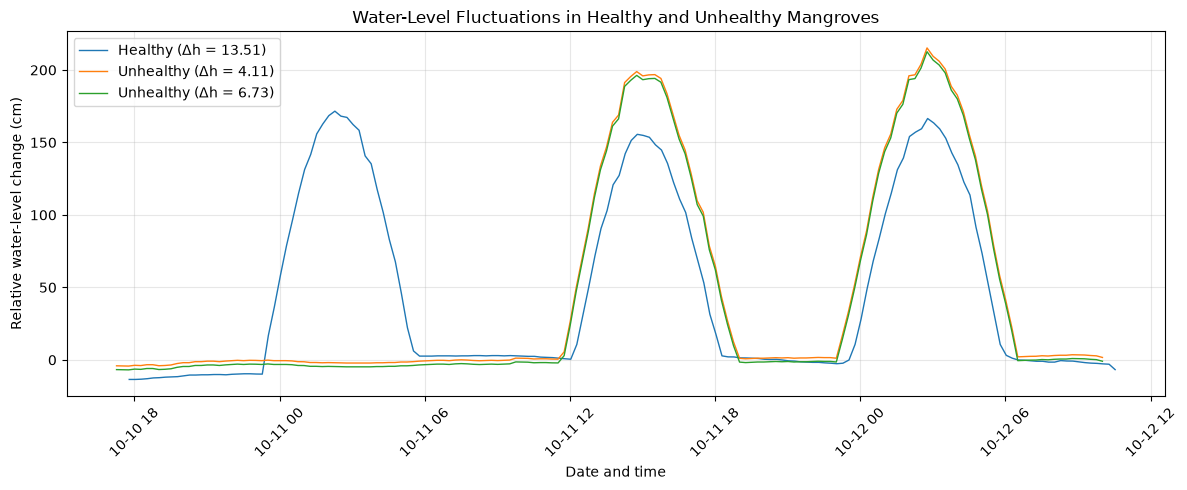

In [27]:
plt.figure(figsize=(12, 5))

# Height difference (delta_h, cm) that is subtracted from the relative water level
# Healthy: 1 value, Unhealthy: 2 cases
delta_h = {
    "Healthy": [13.51],
    "Unhealthy": [4.11, 6.73],
}

for section, file in files.items():
    df = pd.read_csv(file, skiprows=51, encoding="latin1")
    df = df[df["Date/time"].str.contains(r"\d{4}/\d{2}/\d{2}", na=False)].copy()

    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(df["Pressure[cmH2O]"], errors="coerce")
    df = df.dropna(subset=["Date/time", "Pressure[cmH2O]"])
    df = df.sort_values("Date/time")

    # Relative water level (cm), w.r.t. the first measurement
    wl_rel = df["Pressure[cmH2O]"] - df["Pressure[cmH2O]"].iloc[0]

    for dh in delta_h[section]:
        df["Water level (cm)"] = wl_rel - dh

        plt.plot(
            df["Date/time"],
            df["Water level (cm)"],
            label=f"{section} (Δh = {dh})",
            linewidth=1
        )

        interval_h = 0.25  # one measurement every 15 minutes

        dry_time = (df["Water level (cm)"] < 0).sum() * interval_h
        inundation_time = (df["Water level (cm)"] >= 0).sum() * interval_h

        print(f"{section} (Δh = {dh}): Dry time = {dry_time:.1f} h, "
              f"Inundation time = {inundation_time:.1f} h "
              f"({100 * inundation_time / (dry_time + inundation_time):.1f}% inundated)")

plt.xlabel("Date and time")
plt.ylabel("Relative water-level change (cm)")
plt.title("Water-Level Fluctuations in Healthy and Unhealthy Mangroves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
figures["waterlevel_inundation"] = plt.gcf()
plt.show()

# Flow velocity statistics (ECO 0892 / ECO 0885)

### Splitting up of the files into healthy, unhealthy and offshore

This notebook section compares flow velocities (upper, middle and lower layer) of the **healthy** mangroves behind the breakwater, the **unhealthy** mangroves behind the breakwater and the **offshore** location, and estimates the flow reduction and the bed shear stress.

The raw exports (`.csv`) contain several blocks below each other: upper, middle and lower flow velocity, temperature, pressure and tilt. `read_block(first_row, last_row)` reads one block. `first_row` is the line with the column names, `last_row` is the last data line.

In the ECO 0892 file the healthy and the offshore data are in the same blocks: healthy comes first, offshore follows. The offshore data are therefore the same block with the first rows (`iloc[...]`) dropped. The same structure holds for the unhealthy mangroves, founds in the ECO 0885 file. 


In [28]:
# Split up csv file in several parts: upper flow velocity; middle flow velocity; lower flow velocity; temperature; pressure; tilt
# Split up csv file in healthy mangroves behind breakwater and unhealthy mangroves offshore

fname = data_folder / 'ECO_0892_healthy_behindbreakwater_and_unhealthy_offshore_chartdata.csv'
fmt = '%m/%d/%Y %H:%M'   # month/day/year, hour:minute

def read_block(first_row, last_row):
    # first_row = line with the column names, last_row = last data line of the block
    rows = np.arange(first_row, last_row + 1)
    df = pd.read_csv(fname, skiprows=lambda x: x not in rows)
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
    df['Time (localtime)'] = pd.to_datetime(df['Time (localtime)'], format=fmt)
    return df.sort_values('Time (localtime)').reset_index(drop=True)

# Healthy mangroves behind breakwater
upper_fv_healthy  = read_block(1, 26)
middle_fv_healthy = read_block(204, 238) 
lower_fv_healthy  = read_block(430, 477)
temperature_healthy = read_block(695, 907)
pressure_healthy = read_block(1183, 1395)
tilt_healthy = read_block(1671, 1883)

# "Offshore" after breakwater: same blocks, but without the first rows (iloc[n:]),
# which belong to the healthy period

upper_fv_offshore  = read_block(1, 201).iloc[25:].reset_index(drop=True)
middle_fv_offshore = read_block(204, 427).iloc[34:].reset_index(drop=True)
lower_fv_offshore  = read_block(430, 692).iloc[52:].reset_index(drop=True)
temperature_offshore = read_block(695, 1180).iloc[210:].reset_index(drop=True)
pressure_offshore = read_block(1183, 1669).iloc[210:].reset_index(drop=True)
tilt_offshore = read_block(1671, 2156).iloc[210:].reset_index(drop=True)


#### Unhealthy mangroves behind the breakwater (ECO 0885)

Separate file with a different time format (`hour:min:sec day/month/year`). Same idea: one function that reads a block, one line per layer.

In [29]:
# Split up csv file in several parts: upper flow velocity; middle flow velocity; lower flow velocity; temperature; pressure; tilt

dname = data_folder / 'ECO_0885_unhealthy_behindbreakwater_chartdata.csv'
dmt = '%H:%M:%S %d/%m/%Y'   # hour:min:sec day/month/year

def read_block_unhealthy(first_row, last_row):
    rows = np.arange(first_row, last_row + 1)
    dd = pd.read_csv(dname, skiprows=lambda x: x not in rows)
    dd['Time (localtime)'] = pd.to_datetime(dd['Time (localtime)'], format=dmt)
    return dd.sort_values('Time (localtime)').reset_index(drop=True)

# Unhealthy mangroves behind breakwater

upper_fv    = read_block_unhealthy(2, 90)
middle_fv   = read_block_unhealthy(92, 189)
lower_fv    = read_block_unhealthy(191, 311)


### Plotting of healthy vs. offshore

Time series per layer. `break_gaps` inserts a NaN wherever the data has a gap larger than 15 minutes, so the line is not drawn across the gap. 

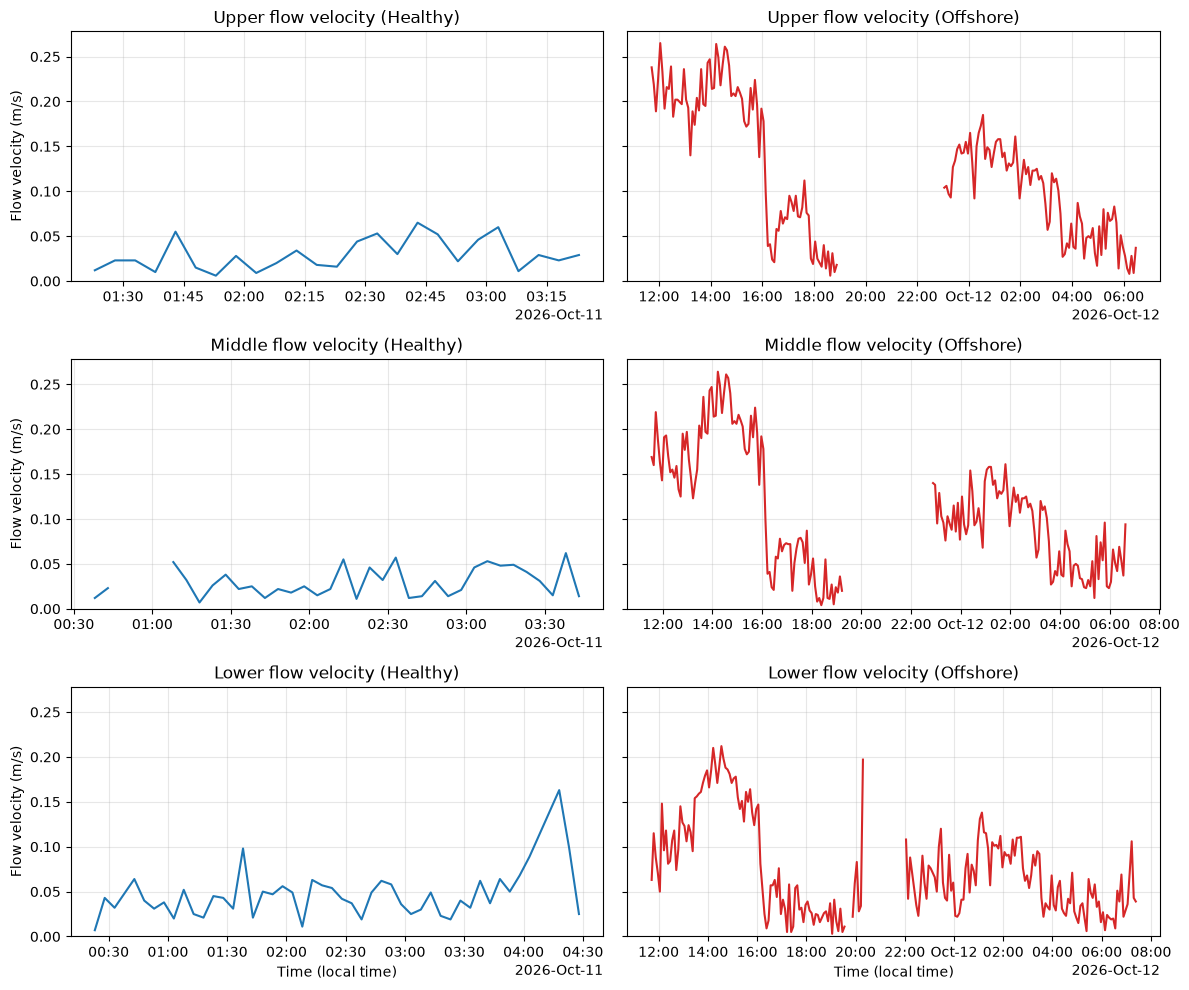

In [30]:
# Draws a line break at data gaps (> max_gap) instead of connecting the points
def break_gaps(df, max_gap='15min'):
    d = df[['Time (localtime)', 'Speed (m/s)']]
    t = d['Time (localtime)']
    gaps = d.index[t.diff() > pd.Timedelta(max_gap)]
    breaks = pd.DataFrame({'Time (localtime)': t[gaps] - pd.Timedelta('1s'),
                           'Speed (m/s)': np.nan})
    return pd.concat([d, breaks]).sort_values('Time (localtime)')

layers = ['Upper', 'Middle', 'Lower']
healthy   = [upper_fv_healthy,   middle_fv_healthy,   lower_fv_healthy]
unhealthy = [upper_fv_offshore, middle_fv_offshore, lower_fv_offshore]
conditions = [('Healthy', 'tab:blue', healthy),
              ('Offshore', 'tab:red', unhealthy)]

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True)

for col, (label, color, dfs) in enumerate(conditions):
    for row, (layer, df) in enumerate(zip(layers, dfs)):
        ax = axes[row, col] 
        d = break_gaps(df)
        ax.plot(d['Time (localtime)'], d['Speed (m/s)'], color=color, lw=1.5)
        ax.set_title(f'{layer} flow velocity ({label})')
        ax.grid(alpha=0.3)

        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

        if col == 0:
            ax.set_ylabel('Flow velocity (m/s)')
        if row == len(layers) - 1:
            ax.set_xlabel('Time (local time)')

axes[0, 0].set_ylim(bottom=0)   # sharey=True applies this to all panels

fig.tight_layout()
figures["flow_velocity_healthy_vs_offshore"] = fig
plt.show()

### Plotting of unhealthy vs. offshore

Same figure, now for the unhealthy mangroves behind the breakwater against offshore.

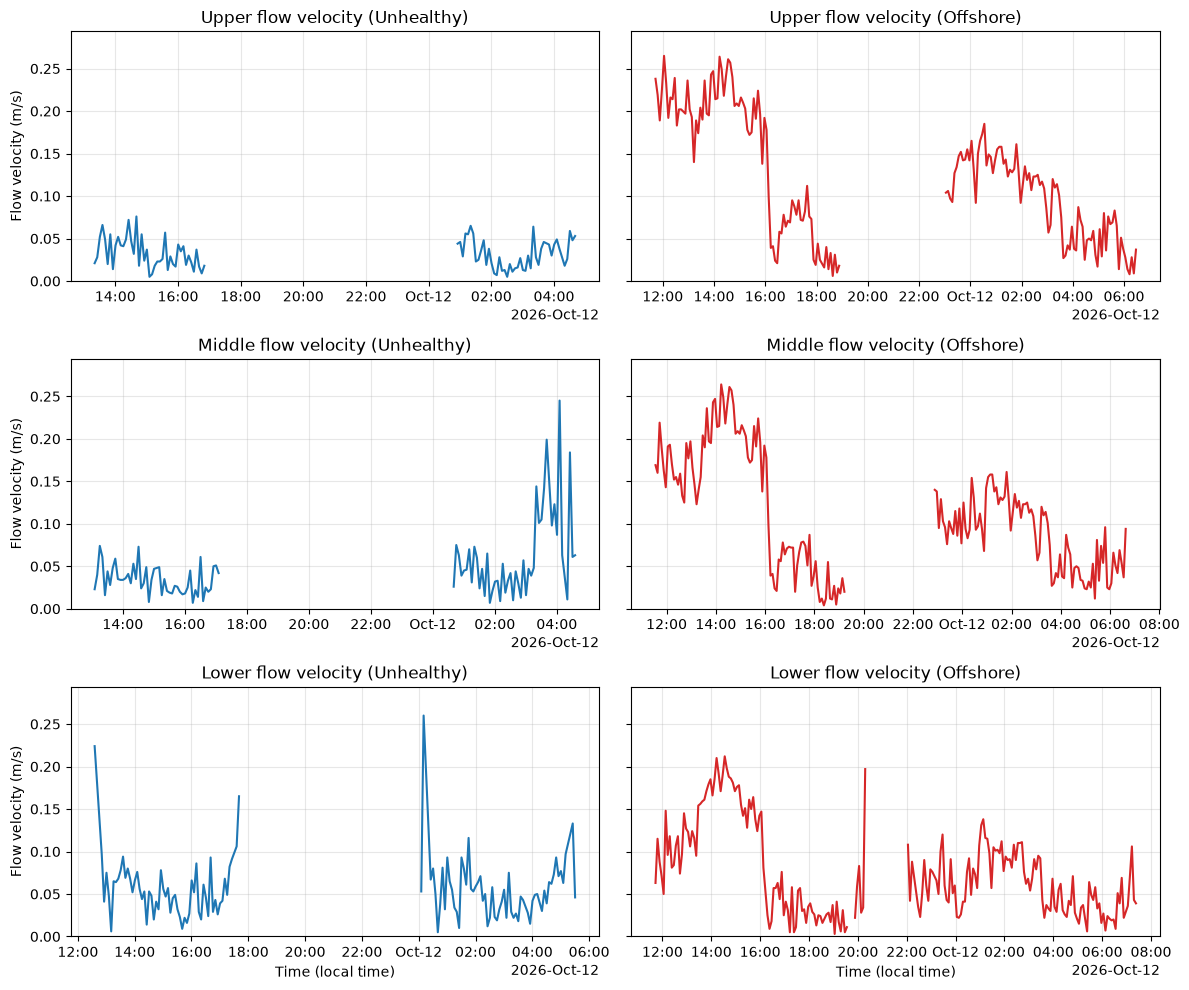

In [31]:
def break_gaps(df, max_gap='15min'):
    d = df[['Time (localtime)', 'Speed (m/s)']]
    t = d['Time (localtime)']
    gaps = d.index[t.diff() > pd.Timedelta(max_gap)]
    breaks = pd.DataFrame({'Time (localtime)': t[gaps] - pd.Timedelta('1s'),
                           'Speed (m/s)': np.nan})
    return pd.concat([d, breaks]).sort_values('Time (localtime)')

layers = ['Upper', 'Middle', 'Lower']
unhealthy   = [upper_fv,   middle_fv,   lower_fv]
offshore = [upper_fv_offshore, middle_fv_offshore, lower_fv_offshore]
conditions = [('Unhealthy', 'tab:blue', unhealthy),
              ('Offshore', 'tab:red', offshore)]

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True)

for col, (label, color, dfs) in enumerate(conditions):
    for row, (layer, df) in enumerate(zip(layers, dfs)):
        ax = axes[row, col] 
        d = break_gaps(df)
        ax.plot(d['Time (localtime)'], d['Speed (m/s)'], color=color, lw=1.5)
        ax.set_title(f'{layer} flow velocity ({label})')
        ax.grid(alpha=0.3)

        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

        if col == 0:
            ax.set_ylabel('Flow velocity (m/s)')
        if row == len(layers) - 1:
            ax.set_xlabel('Time (local time)')

axes[0, 0].set_ylim(bottom=0)   # sharey=True applies this to all panels

fig.tight_layout()
figures["flow_velocity_unhealthy_vs_offshore"] = fig
plt.show()

#### Behind the breakwater vs. offshore in one plot

Both series are averaged to 5-minute values. The grey area is the difference, and the title gives the mean reduction behind the breakwater (only for moments where both have data).

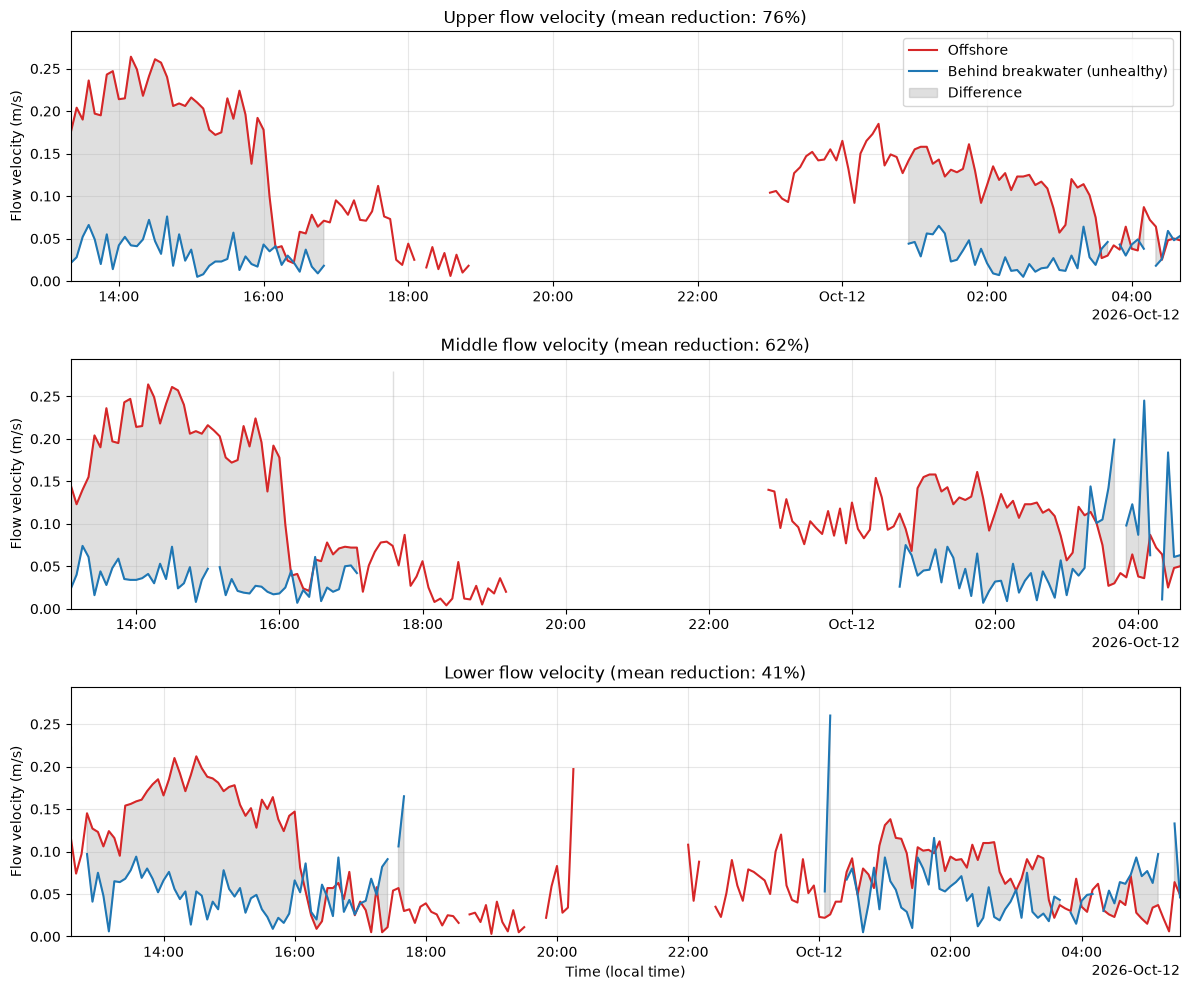

In [32]:
def to_5min(df):
    return df.set_index('Time (localtime)')['Speed (m/s)'].resample('5min').mean()

layers = ['Upper', 'Middle', 'Lower']

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharey=True)

for ax, layer, b, o in zip(axes, layers, unhealthy, offshore):
    both = to_5min(b).to_frame('behind').join(to_5min(o).rename('offshore'), how='inner')

    # Mean reduction at the moments where both series have data
    pairs = both.dropna()
    red = 100 * (1 - pairs['behind'].mean() / pairs['offshore'].mean())

    ax.plot(both.index, both['offshore'], color='tab:red', lw=1.5, label='Offshore')
    ax.plot(both.index, both['behind'], color='tab:blue', lw=1.5,
            label='Behind breakwater (unhealthy)')
    ax.fill_between(both.index, both['behind'], both['offshore'],
                    color='grey', alpha=0.25, label='Difference')

    ax.set_title(f'{layer} flow velocity (mean reduction: {red:.0f}%)')
    ax.set_ylabel('Flow velocity (m/s)')
    ax.grid(alpha=0.3)
    ax.set_xlim(both.index[0], both.index[-1])

    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

axes[0].set_ylim(bottom=0)
axes[0].legend(loc='upper right')
axes[-1].set_xlabel('Time (local time)')

fig.tight_layout()
figures["flow_velocity_reduction_unhealthy_vs_offshore"] = fig
plt.show()

### Flow reduction calculation unhealthy mangroves

Two ways of expressing the reduction behind the breakwater (5-minute means, only moments where both series have data):
- `reduction_of_means`: 1 - mean(behind) / mean(offshore)
- `median_per_pair`: median of 1 - behind / offshore per time step

In [33]:
def reduction(behind, offshore, freq='5min'):
    b = behind.set_index('Time (localtime)')['Speed (m/s)'].resample(freq).mean()
    o = offshore.set_index('Time (localtime)')['Speed (m/s)'].resample(freq).mean()
    both = b.to_frame('behind').join(o.rename('offshore'), how='inner').dropna()
    per_pair = 1 - both['behind'] / both['offshore']
    return {'pairs': len(both),
            'reduction_of_means (%)': 100 * (1 - both['behind'].mean() / both['offshore'].mean()),
            'median_per_pair (%)': 100 * per_pair.median()}

for layer, b, o in zip(['Upper', 'Middle', 'Lower'], unhealthy, offshore):
    print(layer, reduction(b, o))

Upper {'pairs': 87, 'reduction_of_means (%)': np.float64(76.37510513036165), 'median_per_pair (%)': 77.36625514403292}
Middle {'pairs': 96, 'reduction_of_means (%)': np.float64(61.50630914826498), 'median_per_pair (%)': 72.2829313043009}
Lower {'pairs': 119, 'reduction_of_means (%)': np.float64(40.85181898846496), 'median_per_pair (%)': 43.42105263157895}


### Healthy vs. unhealthy

Healthy and unhealthy mangroves behind the breakwater next to each other.

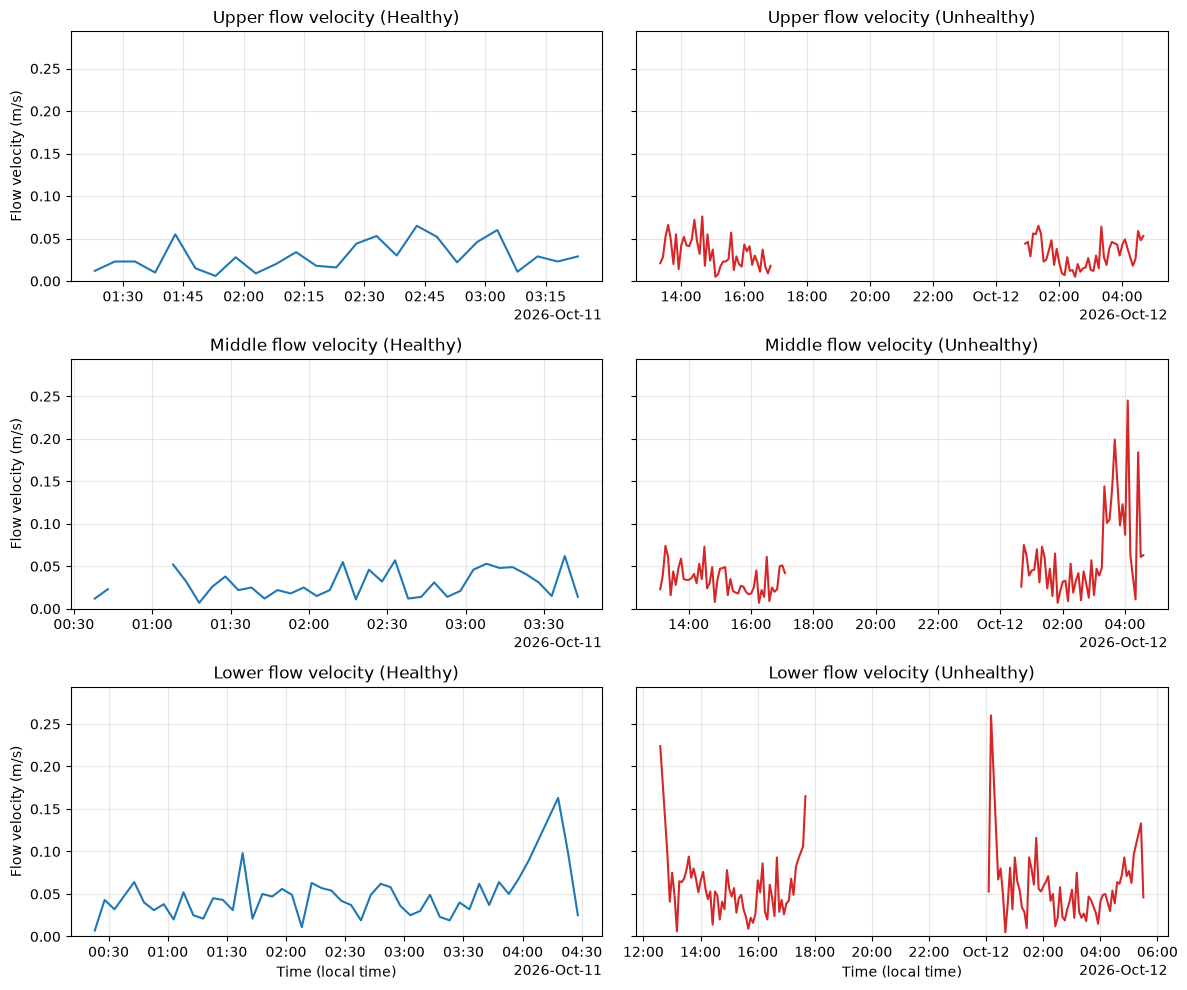

In [34]:
def break_gaps(df, max_gap='15min'):
    d = df[['Time (localtime)', 'Speed (m/s)']]
    t = d['Time (localtime)']
    gaps = d.index[t.diff() > pd.Timedelta(max_gap)]
    breaks = pd.DataFrame({'Time (localtime)': t[gaps] - pd.Timedelta('1s'),
                           'Speed (m/s)': np.nan})
    return pd.concat([d, breaks]).sort_values('Time (localtime)')

layers = ['Upper', 'Middle', 'Lower']
healthy   = [upper_fv_healthy,   middle_fv_healthy,   lower_fv_healthy]
unhealthy = [upper_fv, middle_fv, lower_fv]
conditions = [('Healthy', 'tab:blue', healthy),
              ('Unhealthy', 'tab:red', unhealthy)]

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharey=True)

for col, (label, color, dfs) in enumerate(conditions):
    for row, (layer, df) in enumerate(zip(layers, dfs)):
        ax = axes[row, col] 
        d = break_gaps(df)
        ax.plot(d['Time (localtime)'], d['Speed (m/s)'], color=color, lw=1.5)
        ax.set_title(f'{layer} flow velocity ({label})')
        ax.grid(alpha=0.3)

        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

        if col == 0:
            ax.set_ylabel('Flow velocity (m/s)')
        if row == len(layers) - 1:
            ax.set_xlabel('Time (local time)')

axes[0, 0].set_ylim(bottom=0)   # sharey=True applies this to all panels

fig.tight_layout()
figures["flow_velocity_healthy_vs_unhealthy"] = fig
plt.show()

### Calculation of bed shear stress

The bed shear stress is calculated from the flow velocity and the water level:

tau_b = rho * c_f * u²,  with c_f = g * n_M² / h^(1/3)

with u the flow velocity (m/s), h the water depth (m) and n_M the Manning roughness. Each velocity measurement is coupled to the nearest water level (max. 10 minutes apart). tau_b is only calculated when h > 0.

The water levels are calculated from the Diver files in the next cell (relative water level minus Δh, as in the inundation cell).

In [35]:
# Water levels from the Diver files (same definition as the inundation cell: relative level minus delta_h)
def read_diver_wl(file, dh):
    df = pd.read_csv(file, skiprows=51, encoding="latin1")
    df = df[df["Date/time"].str.contains(r"\d{4}/\d{2}/\d{2}", na=False)].copy()
    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(df["Pressure[cmH2O]"], errors="coerce")
    df = df.dropna(subset=["Date/time", "Pressure[cmH2O]"]).sort_values("Date/time")
    df["Water level (cm)"] = df["Pressure[cmH2O]"] - df["Pressure[cmH2O]"].iloc[0] - dh
    return df[["Date/time", "Water level (cm)"]]

waterlevel_healthy = read_diver_wl(files["Healthy"], delta_h["Healthy"][0])
waterlevel_unhealthy = read_diver_wl(files["Unhealthy"], delta_h["Unhealthy"][0])

In [36]:
def bed_shear_stress(u, n_M, h, rho=1025, g=9.81):
    # Manning-based friction coefficient and bed shear stress (Pa)
    c_f = (g * n_M**2) / (h**(1/3))
    tau_b = rho * c_f * u**2
    return tau_b

# Couples every velocity to the nearest water level and calculates tau_b
# (note: add_tau_b always uses rho=1000 unless you pass another value)
def add_tau_b(speed_df, wl_df, speed_time_col, wl_time_col="Date/time",
              n_M=0.03, rho=1000, g=9.81, tolerance="10min"):
    speed_df = speed_df.copy()
    wl_df = wl_df.copy()

    speed_df[speed_time_col] = pd.to_datetime(speed_df[speed_time_col])
    wl_df[wl_time_col] = pd.to_datetime(wl_df[wl_time_col])

    speed_df = speed_df.sort_values(speed_time_col)
    wl_df = wl_df.sort_values(wl_time_col)

    out = pd.merge_asof(
        speed_df,
        wl_df[[wl_time_col, "Water level (cm)"]],
        left_on=speed_time_col,
        right_on=wl_time_col,
        direction="nearest",
        tolerance=pd.Timedelta(tolerance),
    )

    out["h (m)"] = out["Water level (cm)"] / 100

    out["tau_b (Pa)"] = np.nan
    wet = out["h (m)"] > 0
    out.loc[wet, "tau_b (Pa)"] = bed_shear_stress(
        u=out.loc[wet, "Speed (m/s)"],
        n_M=n_M,
        h=out.loc[wet, "h (m)"],
        rho=rho,
        g=g,
    )
    return out

# n_M = 0.03; both cases use middle_fv (the velocities of the unhealthy logger, ECO 0885)
tau_healthy = add_tau_b(middle_fv, waterlevel_healthy, speed_time_col="Time (localtime)")
tau_unhealthy = add_tau_b(middle_fv, waterlevel_unhealthy, speed_time_col="Time (localtime)")

print(f'Bed shear stress (Pa) - Healthy: {tau_healthy["tau_b (Pa)"].max():.3f}')
print(f'Bed shear stress (Pa) - Unhealthy: {tau_unhealthy["tau_b (Pa)"].max():.3f}')

Bed shear stress (Pa) - Healthy: 0.855
Bed shear stress (Pa) - Unhealthy: 0.688


#### Higher roughness (n_M = 0.04)

Same calculation with a higher Manning roughness, as an upper estimate.

In [37]:
tau_unhealthy_max = add_tau_b(middle_fv, waterlevel_unhealthy, speed_time_col="Time (localtime)", n_M=0.04)
tau_healthy_max = add_tau_b(middle_fv, waterlevel_healthy, speed_time_col="Time (localtime)", n_M=0.04)

In [38]:
print(f'Bed shear stress (Pa) - Healthy: {tau_healthy_max["tau_b (Pa)"].max():.3f}')
print(f'Bed shear stress (Pa) - Unhealthy: {tau_unhealthy_max["tau_b (Pa)"].max():.3f}')

Bed shear stress (Pa) - Healthy: 1.520
Bed shear stress (Pa) - Unhealthy: 1.223


# Save figures
Only figures are saved to `results`. No data or tables are written (the data are restricted).

In [39]:
# Save figures and tables (only when SAVE = True)
if SAVE:
    fig_dir.mkdir(parents=True, exist_ok=True)
    table_dir.mkdir(parents=True, exist_ok=True)
    for name, fig in figures.items():
        fig.savefig(fig_dir / f"{name}.png", dpi=300, bbox_inches="tight")
    for name, table in tables.items():
        table.to_csv(table_dir / f"{name}.csv")